```markdown
# Task 1: Movie Genre Classification
This notebook performs text-based movie genre classification using TF-IDF feature extraction and compares three classic models: Multinomial Naive Bayes, Logistic Regression, and Linear SVC.
```

In [1]:
import os
import re
import string
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score, f1_score, precision_score, recall_score, confusion_matrix

# --- File Loading with Colab-friendly Uploads ---
def load_dataset(file_path, is_test=False):
    """
    Loads and parses the text files formatted as:
    ID ::: TITLE ::: GENRE ::: DESCRIPTION
    If it is a test file with potentially missing genre columns, it adjusts parsing.
    """
    data = []
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split(' ::: ')
            if len(parts) >= 4:
                data.append(parts[:4])
            elif len(parts) == 3 and is_test:
                # Case where test file has no genre column: ID ::: TITLE ::: DESCRIPTION
                data.append([parts[0], parts[1], 'Unknown', parts[2]])

    df = pd.DataFrame(data, columns=['ID', 'TITLE', 'GENRE', 'DESCRIPTION'])
    df['ID'] = df['ID'].astype(int)
    return df

train_path = '/content/train_data.txt'
test_path = '/content/test_data_solution.txt'

# Check if files exist locally; if not, request interactive upload.
# Alternative Google Drive path template:
# from google.colab import drive
# drive.mount('/content/drive')
# train_path = '/content/drive/MyDrive/movie_genre/train_data.txt'

for path, name in [(train_path, 'train_data.txt'), (test_path, 'test_data_solution.txt')]:
    if not os.path.exists(path):
        print(f"'{name}' not found locally at {path}. Please upload it:")
        uploaded = files.upload()
        # Move uploaded file to /content/ if needed
        for filename in uploaded.keys():
            if filename != name:
                os.rename(filename, path)

train_df = load_dataset(train_path, is_test=False)
test_df = load_dataset(test_path, is_test=True)

print(f"Training set shape: {train_df.shape}")
print(f"Test set shape: {test_df.shape}")
display(train_df.head())

'train_data.txt' not found locally at /content/train_data.txt. Please upload it:


Saving train_data.txt to train_data.txt
'test_data_solution.txt' not found locally at /content/test_data_solution.txt. Please upload it:


Saving test_data_solution.txt to test_data_solution.txt
Training set shape: (54214, 4)
Test set shape: (54200, 4)


,ID,TITLE,GENRE,DESCRIPTION
0,1,Oscar et la dame rose (2009),drama,Listening in to a conversation between his doc...
1,2,Cupid (1997),thriller,A brother and sister with a past incestuous re...
2,3,"Young, Wild and Wonderful (1980)",adult,As the bus empties the students for their fiel...
3,4,The Secret Sin (1915),drama,To help their unemployed father make ends meet...
4,5,The Unrecovered (2007),drama,The film's title refers not only to the un-rec...


In [2]:
# --- Data Preprocessing ---
def clean_text(text):
    text = text.lower()
    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Normalize whitespaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text

print("Cleaning text fields...")
train_df['CLEAN_TITLE'] = train_df['TITLE'].apply(clean_text)
train_df['CLEAN_DESC'] = train_df['DESCRIPTION'].apply(clean_text)

test_df['CLEAN_TITLE'] = test_df['TITLE'].apply(clean_text)
test_df['CLEAN_DESC'] = test_df['DESCRIPTION'].apply(clean_text)

# Feature Configuration: Option to test description only or title + description combo
COMBINE_FEATURES = True

if COMBINE_FEATURES:
    train_df['X_text'] = train_df['CLEAN_TITLE'] + " " + train_df['CLEAN_DESC']
    test_df['X_text'] = test_df['CLEAN_TITLE'] + " " + test_df['CLEAN_DESC']
else:
    train_df['X_text'] = train_df['CLEAN_DESC']
    test_df['X_text'] = test_df['CLEAN_DESC']

# --- Vectorization ---
print("Vectorizing text datasets using TF-IDF...")
vectorizer = TfidfVectorizer(ngram_range=(1, 2), stop_words='english', sublinear_tf=True, max_features=50000)

X_train = vectorizer.fit_transform(train_df['X_text'])
X_test = vectorizer.transform(test_df['X_text'])

y_train = train_df['GENRE']
y_test = test_df['GENRE']

print(f"TF-IDF feature matrix shape: {X_train.shape}")

Cleaning text fields...
Vectorizing text datasets using TF-IDF...
TF-IDF feature matrix shape: (54214, 50000)


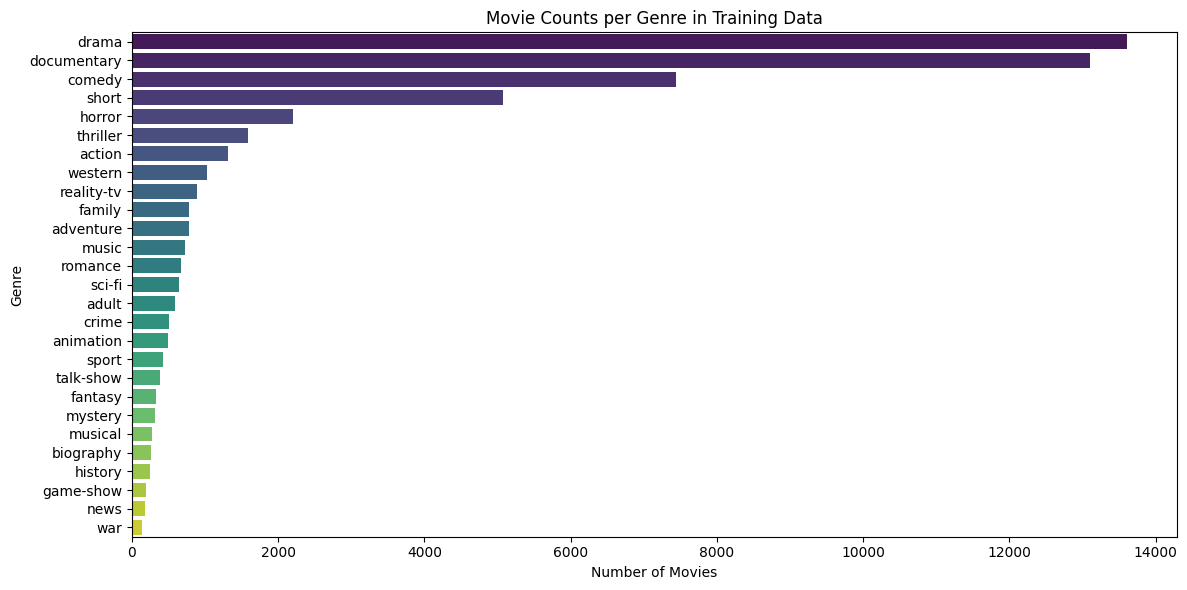

In [3]:
# --- Visualization 1: Genre Distribution Chart ---
plt.figure(figsize=(12, 6))
genre_counts = train_df['GENRE'].value_counts()
sns.barplot(x=genre_counts.values, y=genre_counts.index, hue=genre_counts.index, palette='viridis', legend=False)
plt.title('Movie Counts per Genre in Training Data')
plt.xlabel('Number of Movies')
plt.ylabel('Genre')
plt.tight_layout()
plt.savefig('genre_distribution.png')
plt.show()

In [4]:
# --- Model Training & Evaluation ---
models = {
    'Multinomial Naive Bayes': MultinomialNB(alpha=0.1),
    'Logistic Regression': LogisticRegression(C=1.0, max_iter=1000, solver='saga', n_jobs=-1),
    'Linear SVC': LinearSVC(C=0.5, random_state=42, dual='auto')
}

results = {}
predictions = {}

for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    predictions[model_name] = preds

    # Metrics calculation
    acc = accuracy_score(y_test, preds)
    macro_prec = precision_score(y_test, preds, average='macro', zero_division=0)
    macro_rec = recall_score(y_test, preds, average='macro', zero_division=0)
    macro_f1 = f1_score(y_test, preds, average='macro', zero_division=0)
    weighted_f1 = f1_score(y_test, preds, average='weighted', zero_division=0)

    results[model_name] = {
        'Accuracy': acc,
        'Macro Precision': macro_prec,
        'Macro Recall': macro_rec,
        'Macro F1-Score': macro_f1,
        'Weighted F1-Score': weighted_f1
    }

# Display model comparison table
results_df = pd.DataFrame(results).T
display(results_df)

Training Multinomial Naive Bayes...
Training Logistic Regression...
Training Linear SVC...


,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Weighted F1-Score
Multinomial Naive Bayes,0.569373,0.517415,0.212273,0.246602,0.510587
Logistic Regression,0.599410,0.592266,0.239670,0.280650,0.553006
Linear SVC,0.608247,0.539248,0.318099,0.361122,0.576972


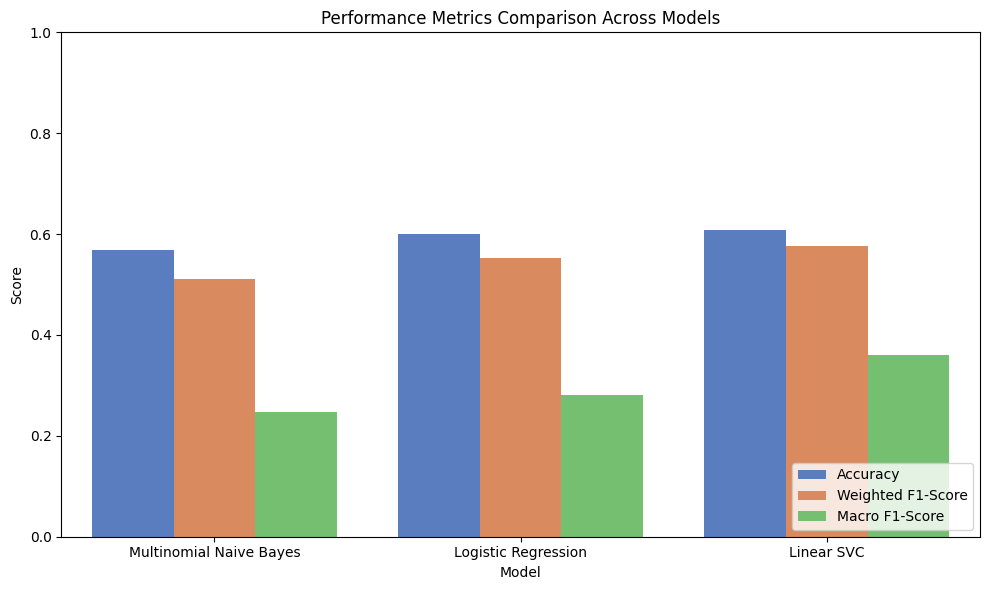

In [5]:
# --- Visualization 2: Model Metrics Comparison Chart ---
metrics_to_plot = ['Accuracy', 'Weighted F1-Score', 'Macro F1-Score']
plot_data = results_df[metrics_to_plot].reset_index().rename(columns={'index': 'Model'})
plot_data_melted = plot_data.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(10, 6))
sns.barplot(data=plot_data_melted, x='Model', y='Score', hue='Metric', palette='muted')
plt.title('Performance Metrics Comparison Across Models')
plt.ylim(0, 1.0)
plt.ylabel('Score')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('model_metrics_comparison.png')
plt.show()

Best performing model: Linear SVC

Detailed Classification Report for Linear SVC:
              precision    recall  f1-score   support

      action       0.48      0.35      0.40      1314
       adult       0.69      0.43      0.53       590
   adventure       0.61      0.23      0.34       775
   animation       0.47      0.12      0.19       498
   biography       0.00      0.00      0.00       264
      comedy       0.56      0.61      0.58      7446
       crime       0.34      0.05      0.09       505
 documentary       0.69      0.86      0.77     13096
       drama       0.57      0.75      0.65     13612
      family       0.51      0.15      0.24       783
     fantasy       0.44      0.09      0.15       322
   game-show       0.83      0.68      0.75       193
     history       0.40      0.01      0.02       243
      horror       0.63      0.67      0.65      2204
       music       0.65      0.54      0.59       731
     musical       0.38      0.06      0.11       276

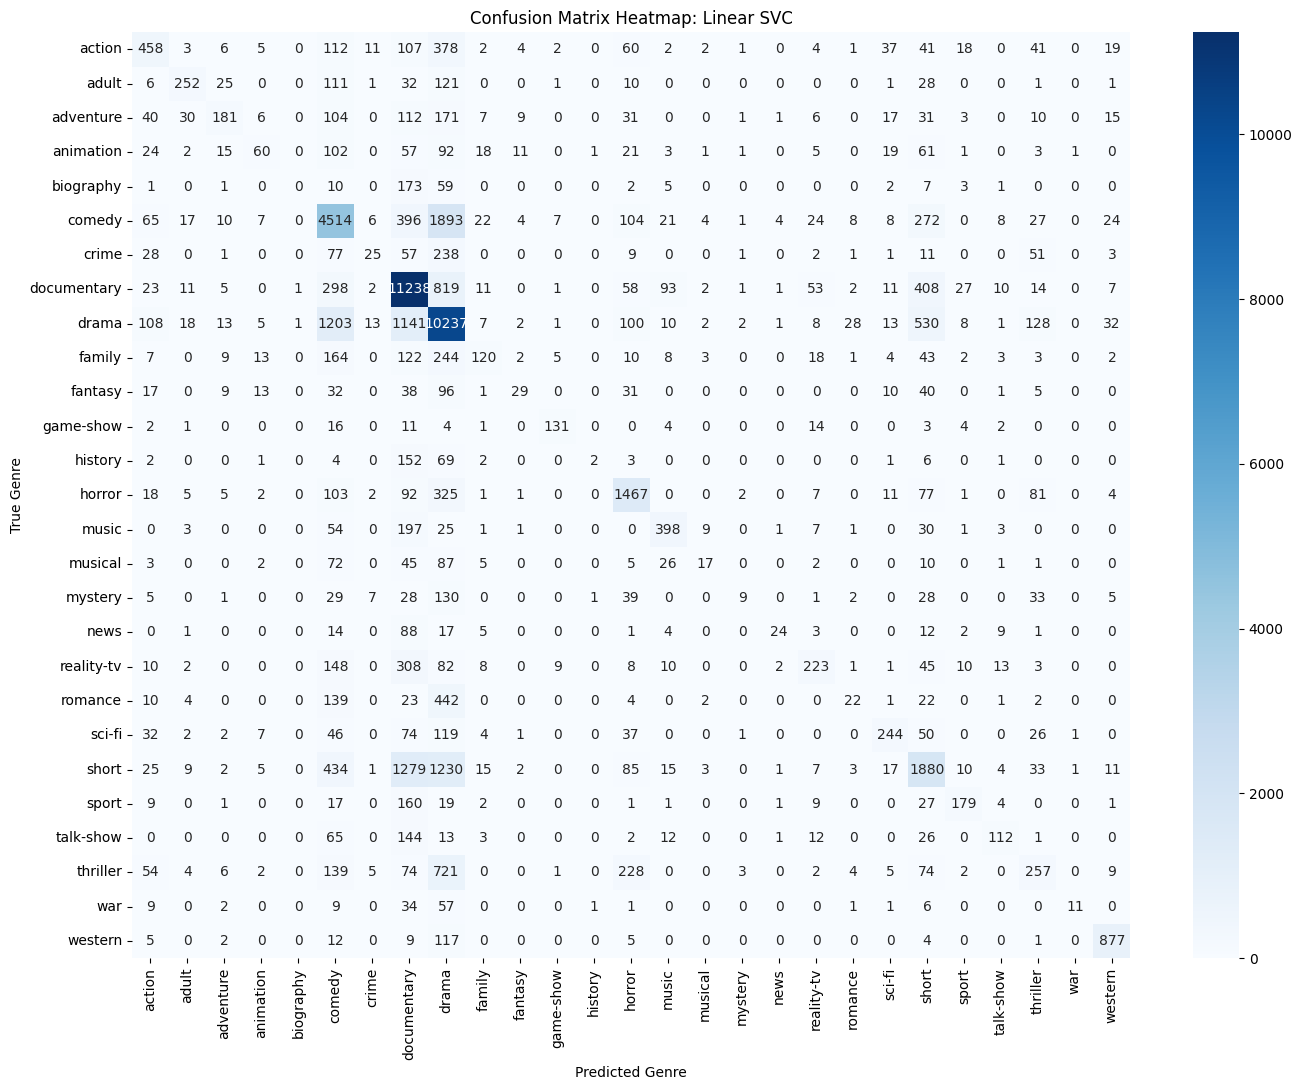

In [6]:
# Determine the best performing model based on Weighted F1-Score
best_model_name = results_df['Weighted F1-Score'].idxmax()
best_preds = predictions[best_model_name]

print(f"Best performing model: {best_model_name}\n")
print(f"Detailed Classification Report for {best_model_name}:")
print(classification_report(y_test, best_preds, zero_division=0))

# --- Visualization 3: Confusion Matrix Heatmap ---
unique_genres = sorted(list(set(y_test)))
cm = confusion_matrix(y_test, best_preds, labels=unique_genres)

plt.figure(figsize=(14, 11))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=unique_genres, yticklabels=unique_genres, cmap='Blues')
plt.title(f'Confusion Matrix Heatmap: {best_model_name}')
plt.ylabel('True Genre')
plt.xlabel('Predicted Genre')
plt.tight_layout()
plt.savefig('confusion_matrix_heatmap.png')
plt.show()

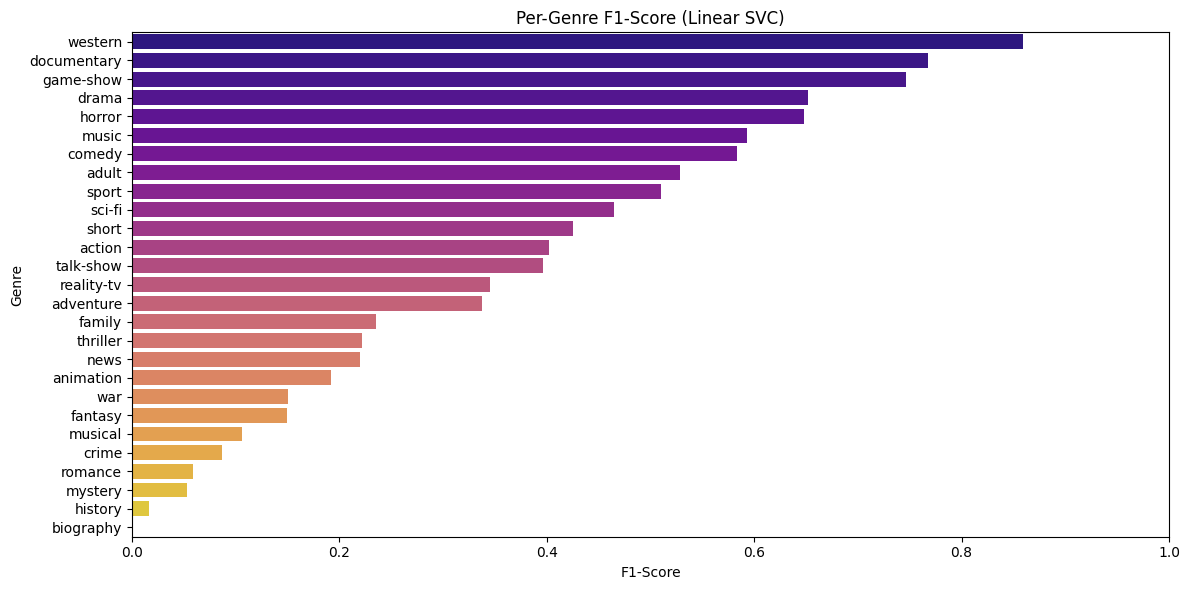

In [7]:
# --- Visualization 4: Per-Genre F1-Score Chart ---
report_dict = classification_report(y_test, best_preds, output_dict=True, zero_division=0)
genre_f1_scores = {k: v['f1-score'] for k, v in report_dict.items() if k in unique_genres}
sorted_genre_f1 = sorted(genre_f1_scores.items(), key=lambda x: x[1], reverse=True)
genres_sorted, f1_sorted = zip(*sorted_genre_f1)

plt.figure(figsize=(12, 6))
sns.barplot(x=list(f1_sorted), y=list(genres_sorted), hue=list(genres_sorted), palette='plasma', legend=False)
plt.title(f'Per-Genre F1-Score ({best_model_name})')
plt.xlabel('F1-Score')
plt.ylabel('Genre')
plt.xlim(0, 1.0)
plt.tight_layout()
plt.savefig('per_genre_f1_scores.png')
plt.show()

In [8]:
# --- Custom Movie Prediction Function ---
def predict_movie(title, description):
    """
    Cleans input fields, builds combined textual feature representation,
    and uses the best-trained model to output predictions with metrics.
    """
    best_clf = models[best_model_name]

    clean_t = clean_text(title)
    clean_d = clean_text(description)

    if COMBINE_FEATURES:
        combined_text = clean_t + " " + clean_d
    else:
        combined_text = clean_d

    vectorized_input = vectorizer.transform([combined_text])
    predicted_class = best_clf.predict(vectorized_input)[0]

    print(f"--- Prediction for: '{title}' ---")
    print(f"Predicted Genre: {predicted_class}\n")

    # Attempt to fetch confidence scores if model supports decision_function or predict_proba
    if hasattr(best_clf, "predict_proba"):
        probs = best_clf.predict_proba(vectorized_input)[0]
        classes = best_clf.classes_
        top_indices = np.argsort(probs)[::-1][:3]
        print("Top 3 Candidate Genres (Probability/Confidence):")
        for idx in top_indices:
            print(f" - {classes[idx]}: {probs[idx]:.4f}")
    elif hasattr(best_clf, "decision_function"):
        scores = best_clf.decision_function(vectorized_input)[0]
        classes = best_clf.classes_
        top_indices = np.argsort(scores)[::-1][:3]
        print("Top 3 Candidate Genres (Decision Scores):")
        for idx in top_indices:
            print(f" - {classes[idx]}: {scores[idx]:.4f}")
    else:
        print("Confidence scoring not available for this classifier.")
    print("-" * 40)

# Test with custom plot summary
predict_movie(
    title="The Galactic Horizon",
    description="A brilliant starship captain is forced out of retirement to stop an ancient alien armada threatening to consume humanity's outer solar system colonies."
)

--- Prediction for: 'The Galactic Horizon' ---
Predicted Genre: sci-fi

Top 3 Candidate Genres (Decision Scores):
 - sci-fi: 0.4809
 - thriller: -0.7940
 - drama: -0.8837
----------------------------------------


In [9]:
# --- Conclusion Section ---
summary_report = f"""
========================================= TASK SUMMARY REPORT =========================================
1. BEST PERFORMING MODEL:
   - Winner: {best_model_name}
   - Accuracy: {results_df.loc[best_model_name, 'Accuracy']:.4f}
   - Weighted F1-Score: {results_df.loc[best_model_name, 'Weighted F1-Score']:.4f}
   - Macro F1-Score: {results_df.loc[best_model_name, 'Macro F1-Score']:.4f}

2. IMPACT OF DATASET CLASS IMBALANCE:
   - High-representation genres (like 'drama' and 'documentary') perform exceptionally well, skewing overall metrics.
   - Minority genres suffer from extremely low recall and F1-Scores because TF-IDF + Linear Classifiers bias
     toward majority classes where specific terms are highly frequent.

3. LIMITATIONS & NEXT STEPS:
   - TF-IDF limitations: Ignores contextual word sequences, synonym matching, and semantic word meanings.
   - Next Steps: Utilize Pre-trained Word Embeddings (Word2Vec, GloVe), or implement transformer architectures
     (e.g., fine-tuning DistilBERT or RoBERTa) to capture complex semantic patterns in short descriptions.
========================================================================================================
"""
print(summary_report)


========================================= TASK SUMMARY REPORT =========================================
1. BEST PERFORMING MODEL:
   - Winner: Linear SVC
   - Accuracy: 0.6082
   - Weighted F1-Score: 0.5770
   - Macro F1-Score: 0.3611

2. IMPACT OF DATASET CLASS IMBALANCE:
   - High-representation genres (like 'drama' and 'documentary') perform exceptionally well, skewing overall metrics.
   - Minority genres suffer from extremely low recall and F1-Scores because TF-IDF + Linear Classifiers bias 
     toward majority classes where specific terms are highly frequent.

3. LIMITATIONS & NEXT STEPS:
   - TF-IDF limitations: Ignores contextual word sequences, synonym matching, and semantic word meanings.
   - Next Steps: Utilize Pre-trained Word Embeddings (Word2Vec, GloVe), or implement transformer architectures 
     (e.g., fine-tuning DistilBERT or RoBERTa) to capture complex semantic patterns in short descriptions.

